<a href="https://colab.research.google.com/github/bautylazza/TP1-IA/blob/main/TP1_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico N°1 - Redes Neuronales
---
## Integrantes - Grupo 02
- Bautista Lazzarini - bautylazza@gmail.com
- Franco Mazzuchini francomazzuchini03@gmail.com
- Tomás Alzugaray - tomas_alzugaray@hotmail.com
- Santiago Nicle - niclesantiago@gmail.com
---
## 1. Diseño del Modelo MLP

### Justificación de Decisiones Técnicas

* **Capas Ocultas (2 capas):** Dado que el problema de mantenimiento predictivo implica relaciones no lineales entre temperatura, desgaste y torque, una sola capa podría ser insuficiente. Implementaremos dos capas para permitir que la red aprenda representaciones de características más complejas.

* **Cantidad de Neuronas (16 y 8):** Seguimos una estructura de "embudo". La primera capa tiene 16 neuronas para capturar interacciones entre las 7 variables de entrada, y la segunda reduce a 8 para consolidar esos patrones antes de la decisión final. Esto mantiene el número de parámetros bajo control para evitar el *overfitting* (sobreajuste).


* **Funciones de Activación:**
* **ReLU (Hidden Layers):** Es la más eficiente para evitar el desvanecimiento del gradiente en redes multicapa.
* **Sigmoide (Output Layer):** Como es un problema de clasificación binaria (falla o no falla), necesitamos que la salida sea un valor entre 0 y 1 que represente una probabilidad.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve,accuracy_score, precision_score, recall_score, f1_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Cargamos el dataset que ya tiene el escalado robusto y encoding
df = pd.read_csv('mantenimiento_procesado.csv')

# Separamos la variable objetivo ('target') de las características
X = df.drop('target', axis=1)
y = df['target']

# Replicamos la división 75/25 de Ciencia de Datos para mantener consistencia
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Datos listos. Entrenamiento: {X_train.shape[0]} muestras. Validación: {X_test.shape[0]} muestras.")
df.head()

Datos listos. Entrenamiento: 10890 muestras. Validación: 3631 muestras.


,air_temp [K],process_temp [K],speed [RPM],torque [Nm],tool_wear [min],target,product_type_L,product_type_M
0,0.969697,1.576720,-0.082524,0.284061,0.302326,0,1.0,0.0
1,0.515152,0.465608,1.019417,-0.541820,-0.100775,0,1.0,0.0
2,0.506061,0.608466,-0.946602,1.159916,0.465116,1,0.0,1.0
3,0.530303,0.851852,0.480583,-0.510784,0.674419,1,1.0,0.0
4,-1.181818,-1.280423,1.553398,-0.988953,-0.558140,0,1.0,0.0


In [ ]:
# DISEÑO DE LA ARQUITECTURA (7->16->8->1)
model = keras.Sequential([
    # Capa de entrada implícita con el número de columnas de X_train
    # Primera capa oculta: 16 neuronas
    layers.Dense(16, activation='relu', input_shape=(X_train.shape[1],)),

    # Segunda capa oculta: 8 neuronas
    layers.Dense(8, activation='relu'),

    # Capa de salida: 1 neurona con Sigmoide para clasificación binaria
    layers.Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
#COMPILACIÓN DEL MODELO
model.compile(
    optimizer='adam',
    loss='binary_crossentropy', # Función de error para clasificación binaria
    metrics=['accuracy']
)

# Resumen del modelo para ver la cantidad de parámetros (pesos + bias)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 273 (1.07 KB)

 Trainable params: 273 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ENTRENAMIENTO
# Usamos los mismos conjuntos generados en CD (X_train, y_train)
# Y evaluamos con el conjunto de validación (X_test, y_test)
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=30,          # Número de iteraciones sobre el dataset
    batch_size=32,      # Tamaño del bloque de datos antes de actualizar pesos
    verbose=1
)

Epoch 1/30
341/341 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8096 - loss: 0.4638 - val_accuracy: 0.8675 - val_loss: 0.3271
Epoch 2/30
341/341 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8776 - loss: 0.2867 - val_accuracy: 0.8890 - val_loss: 0.2694
Epoch 3/30
341/341 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8927 - loss: 0.2531 - val_accuracy: 0.8989 - val_loss: 0.2514
Epoch 4/30
341/341 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8998 - loss: 0.2399 - val_accuracy: 0.9055 - val_loss: 0.2417
Epoch 5/30
341/341 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9035 - loss: 0.2315 - val_accuracy: 0.9047 - val_loss: 0.2333
Epoch 6/30
341/341 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9074 - loss: 0.2249 - val_accuracy: 0.9072 - val_loss: 0.2286
Epoch 7/30
341/341 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9099 - loss: 0.2197 - val_accuracy: 0.9116 - val_loss: 0.2232
Epoch 8/30
341/341 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9139 - loss: 0.2141 - val_accuracy: 0.

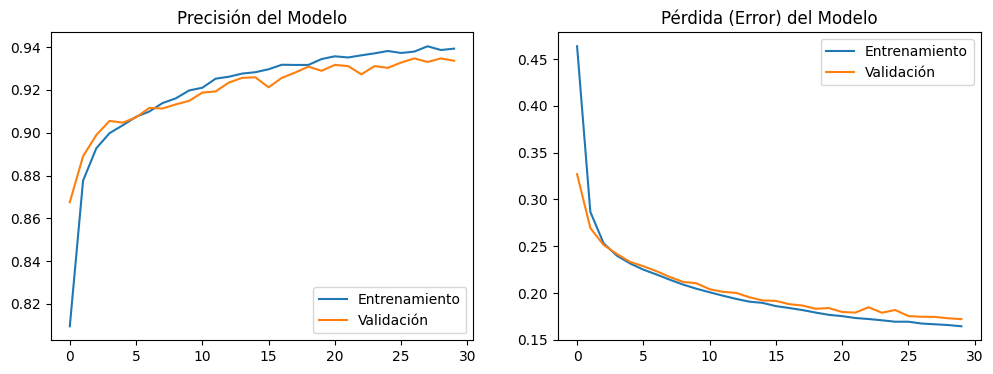

In [ ]:
# 4. VISUALIZACIÓN DEL PROCESO DE APRENDIZAJE
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Precisión del Modelo')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Pérdida (Error) del Modelo')
plt.legend()
plt.show()

## 2. Ajuste de hiperparámetros
En esta sección, se realiza una exploración sistemática de los diferentes componentes que gobiernan el proceso de aprendizaje de la red neuronal. El objetivo no es solo maximizar la precisión, sino comprender cómo la variación de los hiperparámetros afecta la dinámica de convergencia y la capacidad de generalización del modelo.

Para llevar a cabo estas pruebas de manera eficiente y reproducible, se utiliza una función de entrenamiento universal que permite modificar los parámetros de la arquitectura y del algoritmo de optimización de forma parametrizada:

In [ ]:
# el valor en los parametros indica una seleccion base por defecto.
def ejecutar_experimento(id_exp, lr=0.001, batch_size=32, epochs=30, loss='binary_crossentropy', opt='adam', dropout=0.0, l2=0.0):
    # Definición de la arquitectura
    model = keras.Sequential([
        layers.Dense(16, activation='relu', kernel_regularizer=keras.regularizers.l2(l2), input_shape=(X_train.shape[1],)),
        layers.Dropout(dropout),
        layers.Dense(8, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])

    # Configuración del optimizador
    if opt.lower() == 'adam':
        optimizer = keras.optimizers.Adam(learning_rate=lr)
    elif opt.lower() == 'sgd':
        optimizer = keras.optimizers.SGD(learning_rate=lr)
    elif opt.lower() == 'rmsprop':
        optimizer = keras.optimizers.RMSprop(learning_rate=lr)

    model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])

    # Entrenamiento
    history = model.fit(X_train, y_train, validation_data=(X_test, y_test),
                        epochs=epochs, batch_size=batch_size, verbose=0)

    val_acc = history.history['val_accuracy'][-1]
    val_loss = history.history['val_loss'][-1]

    print(f"✅ {id_exp} completado. Val_Acc: {val_acc:.4f} | Val_Loss: {val_loss:.4f}")
    return history, id_exp

### Bloques de Experimentos por Eje

#### Eje A: Tasa de Aprendizaje y Optimizadores

El **optimizador** es el algoritmo encargado de actualizar los pesos sinápticos para minimizar la función de error. Por su parte, la **tasa de aprendizaje** ($\eta$) es un parámetro que determina el tamaño de los pasos realizados en la dirección opuesta al gradiente.

En este eje, realizamos una búsqueda en grilla (*Grid Search*) cruzando tres optimizadores distintos con tres niveles de tasa de aprendizaje:

* **Adam**: Algoritmo que utiliza momentos y tasas adaptativas para cada peso, siendo el estándar actual por su eficiencia.


* **SGD (Descenso de Gradiente Estocástico)**: El método clásico de primer orden que sigue la dirección del gradiente de forma más rígida.


* **RMSprop**: Optimizador que adapta la tasa de aprendizaje basándose en la media móvil de los gradientes recientes, siendo muy robusto ante ruidos.

In [ ]:
# Definimos las listas de parámetros a cruzar
tasas = [0.01, 0.001, 0.0001] # Alta, Estándar, Baja
optimizadores = ['adam', 'sgd', 'rmsprop']

# Diccionario para guardar los resultados
resultados_eje_a = {}

print("--- INICIANDO EXPLORACIÓN DEL EJE A ---")

for opt in optimizadores:
    for lr in tasas:
        nombre_exp = f"Exp_{opt}_lr_{lr}"
        # Explicación de lo que estamos haciendo en cada paso
        print(f"Probando: Optimizador {opt.upper()} con Tasa de Aprendizaje {lr}")

        hist, nom = ejecutar_experimento(nombre_exp, lr=lr, opt=opt)
        resultados_eje_a[nombre_exp] = hist

print("--- EXPLORACIÓN FINALIZADA ---")

--- INICIANDO EXPLORACIÓN DEL EJE A ---
Probando: Optimizador ADAM con Tasa de Aprendizaje 0.01


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_adam_lr_0.01 completado. Val_Acc: 0.9405 | Val_Loss: 0.1399
Probando: Optimizador ADAM con Tasa de Aprendizaje 0.001


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_adam_lr_0.001 completado. Val_Acc: 0.9223 | Val_Loss: 0.1984
Probando: Optimizador ADAM con Tasa de Aprendizaje 0.0001


...

✅ Exp_rmsprop_lr_0.01 completado. Val_Acc: 0.9389 | Val_Loss: 0.1721
Probando: Optimizador RMSPROP con Tasa de Aprendizaje 0.001


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_rmsprop_lr_0.001 completado. Val_Acc: 0.9345 | Val_Loss: 0.1919
Probando: Optimizador RMSPROP con Tasa de Aprendizaje 0.0001


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_rmsprop_lr_0.0001 completado. Val_Acc: 0.8722 | Val_Loss: 0.2927
--- EXPLORACIÓN FINALIZADA ---


Visualización del eje A

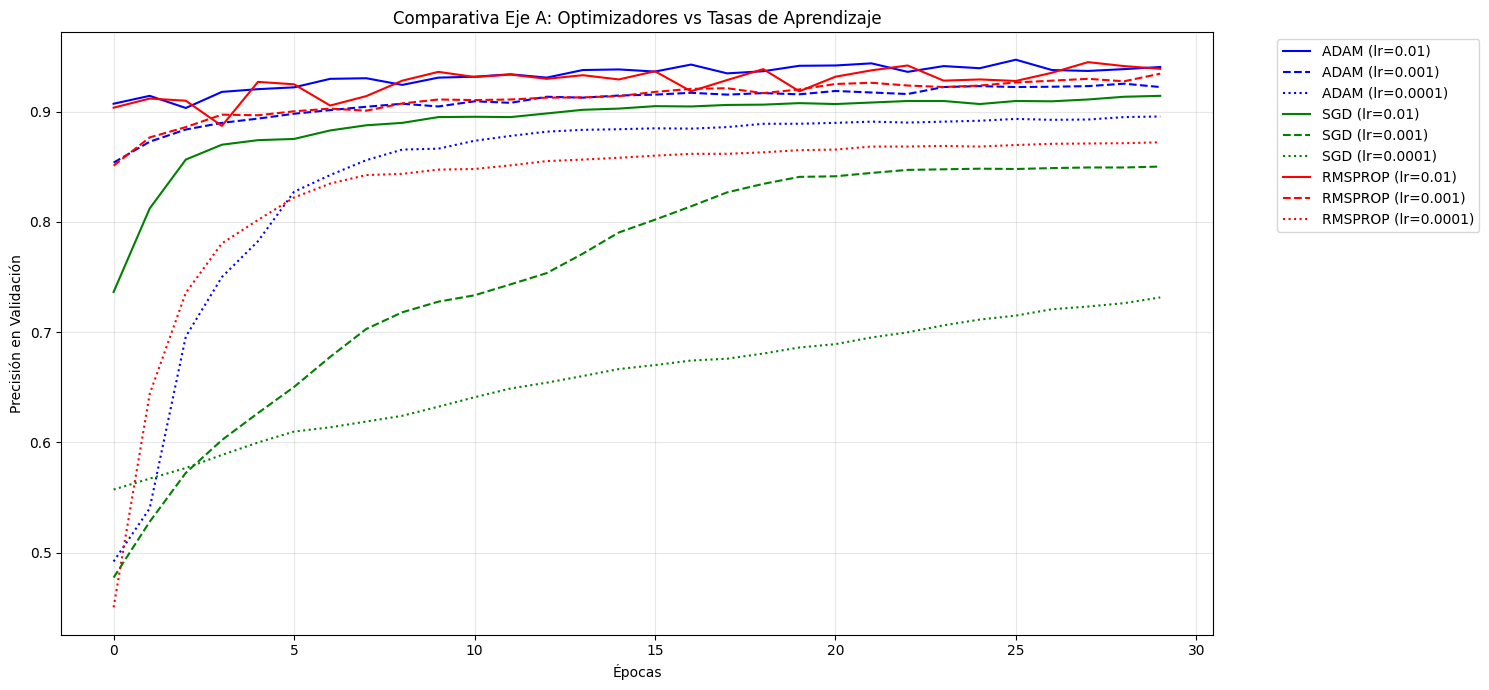

In [ ]:
plt.figure(figsize=(15, 7))

colores = {'adam': 'blue', 'sgd': 'green', 'rmsprop': 'red'}
estilos = {0.01: '-', 0.001: '--', 0.0001: ':'}

for nombre, hist in resultados_eje_a.items():
    # Extraemos el opt y el lr del nombre para configurar el estilo
    partes = nombre.split('_')
    opt = partes[1]
    lr = float(partes[3])

    plt.plot(hist.history['val_accuracy'],
             color=colores[opt],
             linestyle=estilos[lr],
             label=f"{opt.upper()} (lr={lr})")

plt.title('Comparativa Eje A: Optimizadores vs Tasas de Aprendizaje')
plt.xlabel('Épocas')
plt.ylabel('Precisión en Validación')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Eje B: Robustez y Regularización (Dropout y L2)

La regularización es fundamental para evitar el **sobreajuste** (*overfitting*), situación en la que el modelo "memoriza" los datos de entrenamiento pero pierde capacidad para generalizar ante datos nuevos.

Exploramos dos técnicas principales:

* **Dropout**: Técnica que consiste en "apagar" aleatoriamente una fracción de neuronas durante cada paso del entrenamiento, forzando a la red a crear representaciones más robustas y no dependientes de neuronas específicas.


* **Regularización L2**: Añade una penalización a la función de pérdida proporcional al cuadrado de la magnitud de los pesos, manteniendo los parámetros del modelo pequeños y estables.

In [ ]:
# Definimos los niveles de "fuerza" de la regularización
niveles_dropout = [0.0, 0.2, 0.5]  # Nada, Suave, Fuerte
niveles_l2 = [0.0, 0.01, 0.001]    # Nada, Penalización alta, Penalización baja

resultados_eje_b = {}

print("--- INICIANDO EXPLORACIÓN DEL EJE B ---")

for d_rate in niveles_dropout:
    for l2_val in niveles_l2:
        nombre_exp = f"Exp_Drop_{d_rate}_L2_{l2_val}"

        # Explicación del experimento actual
        desc = ""
        if d_rate == 0 and l2_val == 0: desc = "(Modelo Base)"
        elif d_rate > 0 and l2_val > 0: desc = "(Combinación Mixta)"

        print(f"Probando: Dropout={d_rate} + L2={l2_val} {desc}")

        # Ejecutamos usando la función universal (mantenemos lr=0.001 y adam como base)
        hist, nom = ejecutar_experimento(nombre_exp, dropout=d_rate, l2=l2_val)
        resultados_eje_b[nombre_exp] = hist

print("--- EXPLORACIÓN FINALIZADA ---")

--- INICIANDO EXPLORACIÓN DEL EJE B ---
Probando: Dropout=0.0 + L2=0.0 (Modelo Base)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_Drop_0.0_L2_0.0 completado. Val_Acc: 0.9375 | Val_Loss: 0.1757
Probando: Dropout=0.0 + L2=0.01 


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_Drop_0.0_L2_0.01 completado. Val_Acc: 0.9281 | Val_Loss: 0.2031
Probando: Dropout=0.0 + L2=0.001 


...

✅ Exp_Drop_0.5_L2_0.0 completado. Val_Acc: 0.9069 | Val_Loss: 0.2356
Probando: Dropout=0.5 + L2=0.01 (Combinación Mixta)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_Drop_0.5_L2_0.01 completado. Val_Acc: 0.9146 | Val_Loss: 0.2590
Probando: Dropout=0.5 + L2=0.001 (Combinación Mixta)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_Drop_0.5_L2_0.001 completado. Val_Acc: 0.9157 | Val_Loss: 0.2364
--- EXPLORACIÓN FINALIZADA ---


Visualización del eje B

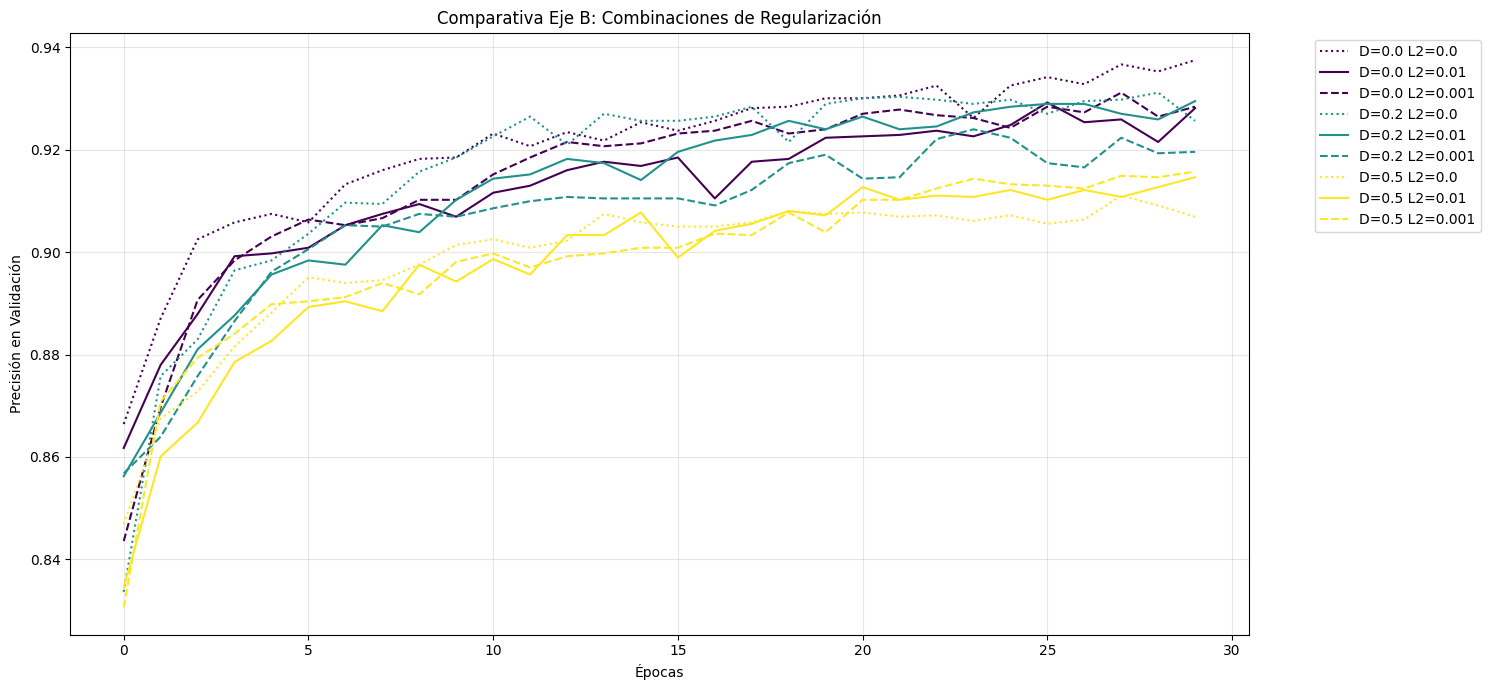

In [ ]:
plt.figure(figsize=(15, 7))

# Usamos un mapa de colores para diferenciar las intensidades de Dropout
import matplotlib.cm as cm
import numpy as np

colors = cm.viridis(np.linspace(0, 1, len(niveles_dropout)))

for i, d_rate in enumerate(niveles_dropout):
    for l2_val in niveles_l2:
        nombre = f"Exp_Drop_{d_rate}_L2_{l2_val}"
        hist = resultados_eje_b[nombre]

        # Estilo de línea según L2
        estilo = '-' if l2_val == 0.01 else '--' if l2_val == 0.001 else ':'

        plt.plot(hist.history['val_accuracy'],
                 label=f"D={d_rate} L2={l2_val}",
                 color=colors[i],
                 linestyle=estilo)

plt.title('Comparativa Eje B: Combinaciones de Regularización')
plt.xlabel('Épocas')
plt.ylabel('Precisión en Validación')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Eje C: Estabilidad y Tiempo (Batch Size y Épocas)

Este eje define la granularidad y la duración del proceso de aprendizaje:

* **Batch Size (Tamaño del Lote)**: Indica cuántas muestras procesa la red antes de realizar una actualización de pesos. Un batch pequeño genera un camino al mínimo más ruidoso pero exploratorio, mientras que un batch grande ofrece una estimación del gradiente más estable y veloz.


* **Épocas**: Representan la cantidad de veces que el algoritmo recorre el conjunto de datos completo. Un número excesivo de épocas puede llevar al sobreajuste, mientras que muy pocas pueden resultar en un modelo que no alcanzó a converger.

In [ ]:
# Definimos los valores a cruzar
tamanos_batch = [16, 64, 256]   # Pequeño (ruidoso), Medio, Grande (estable)
cantidades_epocas = [20, 30, 60] # Corto, Estándar, Largo

resultados_eje_c = {}

print("--- INICIANDO EXPLORACIÓN DEL EJE C ---")

for bs in tamanos_batch:
    for ep in cantidades_epocas:
        nombre_exp = f"Exp_Batch_{bs}_Ep_{ep}"

        # Breve descripción técnica para la consola
        tipo_batch = "Ruidoso" if bs < 32 else "Estable"
        tipo_estudio = "Rápido" if ep < 30 else "Intensivo"
        print(f"Probando: Batch {bs} ({tipo_batch}) | Épocas: {ep} ({tipo_estudio})")

        # Ejecutamos (mantenemos Adam y lr=0.001 como base de comparación)
        hist, nom = ejecutar_experimento(nombre_exp, batch_size=bs, epochs=ep)
        resultados_eje_c[nombre_exp] = hist

print("--- EXPLORACIÓN FINALIZADA ---")

--- INICIANDO EXPLORACIÓN DEL EJE C ---
Probando: Batch 16 (Ruidoso) | Épocas: 20 (Rápido)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_Batch_16_Ep_20 completado. Val_Acc: 0.9284 | Val_Loss: 0.1868
Probando: Batch 16 (Ruidoso) | Épocas: 30 (Intensivo)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_Batch_16_Ep_30 completado. Val_Acc: 0.9361 | Val_Loss: 0.1718
Probando: Batch 16 (Ruidoso) | Épocas: 60 (Intensivo)


...

✅ Exp_Batch_256_Ep_20 completado. Val_Acc: 0.8970 | Val_Loss: 0.2484
Probando: Batch 256 (Estable) | Épocas: 30 (Intensivo)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_Batch_256_Ep_30 completado. Val_Acc: 0.9160 | Val_Loss: 0.2179
Probando: Batch 256 (Estable) | Épocas: 60 (Intensivo)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_Batch_256_Ep_60 completado. Val_Acc: 0.9256 | Val_Loss: 0.2047
--- EXPLORACIÓN FINALIZADA ---


Visualización del eje C

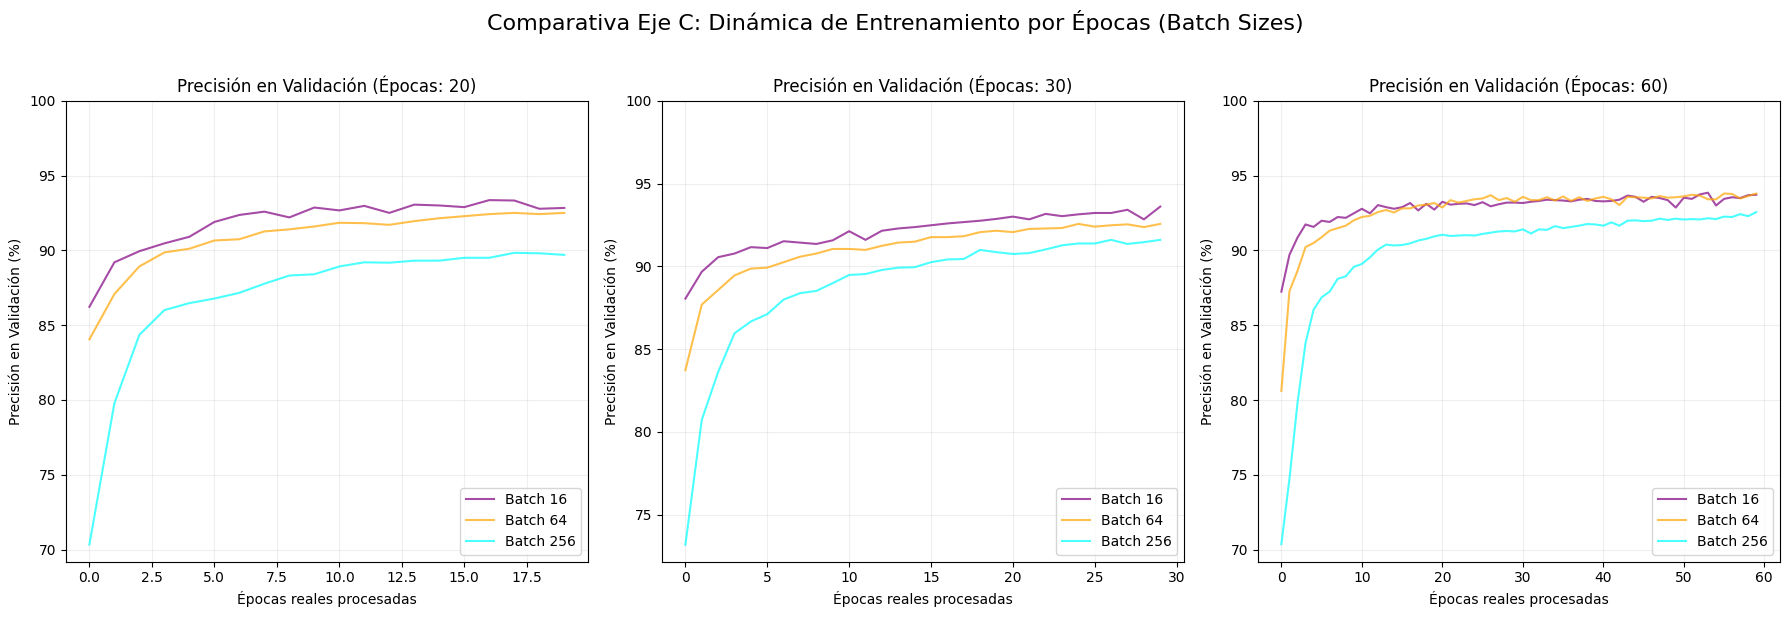

In [ ]:
plt.figure(figsize=(18, 6))

colores_bs = {16: 'purple', 64: 'orange', 256: 'cyan'}

# Agrupamos los resultados por época para facilitar la creación de subplots
histories_by_epoch = {ep: {} for ep in cantidades_epocas}
for nombre, hist in resultados_eje_c.items():
    partes = nombre.split('_')
    bs = int(partes[2])
    ep = int(partes[4])
    histories_by_epoch[ep][bs] = hist

for i, ep in enumerate(cantidades_epocas):
    plt.subplot(1, len(cantidades_epocas), i + 1) # Crear un subplot para cada valor de época
    for bs, hist in histories_by_epoch[ep].items():
        plt.plot([acc * 100 for acc in hist.history['val_accuracy']], # Multiplicar por 100 para escala de 0 a 100
                 label=f"Batch {bs}",
                 color=colores_bs[bs],
                 alpha=0.7)

    plt.title(f'Precisión en Validación (Épocas: {ep})')
    plt.xlabel('Épocas reales procesadas')
    plt.ylabel('Precisión en Validación (%)') # Actualizar la etiqueta del eje Y
    plt.ylim(top=100) # Mantener el límite superior en 100, dejar que el inferior se autoajuste
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.2)

plt.suptitle('Comparativa Eje C: Dinámica de Entrenamiento por Épocas (Batch Sizes)', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

#### Eje D: El Criterio de Error (Función de Pérdida)

La función de pérdida cuantifica la discrepancia entre la salida producida por la red ($\hat{y}$) y la salida deseada ($y$). Es el "faro" que guía el ajuste de los parámetros.

Comparamos dos enfoques distintos:

* **Binary Crossentropy**: El estándar para clasificación binaria que mide la divergencia entre distribuciones de probabilidad, penalizando severamente las predicciones seguras pero incorrectas.


* **Mean Squared Error (MSE)**: Basado en el error cuadrático medio ($E=\frac{1}{2}\sum(y-\hat{y})^2$), es el criterio fundamental de la Regla Delta.

In [ ]:
# Definimos las funciones de pérdida a probar

funciones_loss = ['binary_crossentropy', 'mean_squared_error']
resultados_eje_d = {}

print("--- INICIANDO EXPLORACIÓN DEL EJE D ---")

for f_loss in funciones_loss:
    nombre_exp = f"Exp_Loss_{f_loss}"

    # Explicación para la consola
    if f_loss == 'hinge':
        print(f"Probando: Loss {f_loss.upper()} (Criterio de margen rígido)")
    else:
        print(f"Probando: Loss {f_loss.upper()} (Criterio de distancia/probabilidad)")

    # Ejecutamos (con Adam y lr=0.001 como base)
    hist, nom = ejecutar_experimento(nombre_exp, loss=f_loss)
    resultados_eje_d[nombre_exp] = hist

print("--- EXPLORACIÓN FINALIZADA ---")

--- INICIANDO EXPLORACIÓN DEL EJE D ---
Probando: Loss BINARY_CROSSENTROPY (Criterio de distancia/probabilidad)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_Loss_binary_crossentropy completado. Val_Acc: 0.9292 | Val_Loss: 0.1826
Probando: Loss MEAN_SQUARED_ERROR (Criterio de distancia/probabilidad)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Exp_Loss_mean_squared_error completado. Val_Acc: 0.9361 | Val_Loss: 0.0513
--- EXPLORACIÓN FINALIZADA ---


Visualización del eje D

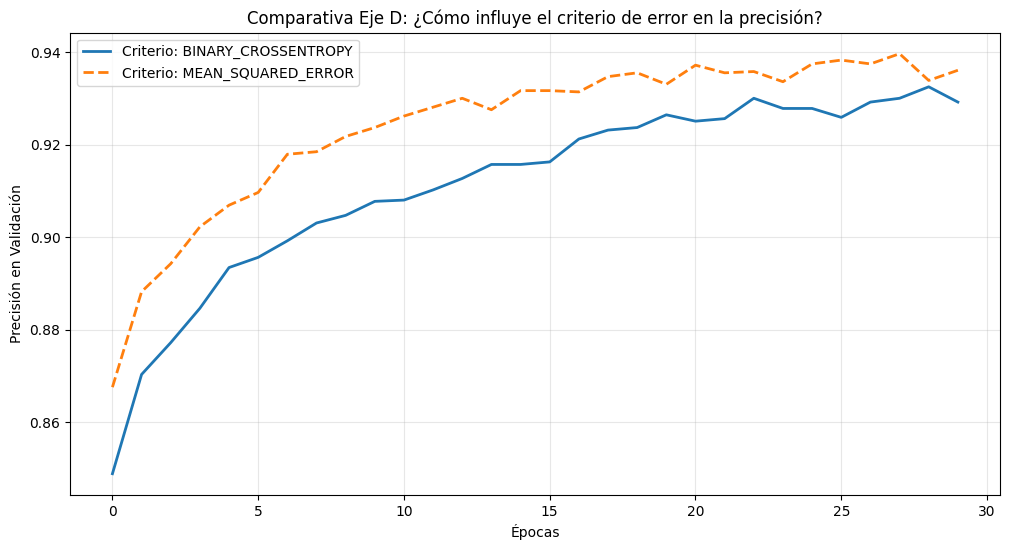

In [ ]:
plt.figure(figsize=(12, 6))

estilos = {'binary_crossentropy': '-', 'mean_squared_error': '--'}

for nombre, hist in resultados_eje_d.items():
    f_loss = nombre.split('_')[2]
    if len(nombre.split('_')) > 3: # Para manejar nombres con guiones bajos
        f_loss = "_".join(nombre.split('_')[2:])

    plt.plot(hist.history['val_accuracy'],
             label=f"Criterio: {f_loss.upper()}",
             linestyle=estilos.get(f_loss, '-'),
             linewidth=2)

plt.title('Comparativa Eje D: ¿Cómo influye el criterio de error en la precisión?')
plt.xlabel('Épocas')
plt.ylabel('Precisión en Validación')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Seccion 3: Evaluacion del Modelo

Se eligio la siguiente configuracion de hiperparametros:

Adam con lr=0.01, dropout=0, l2=0, batch=16, epocas=30, función de perdida=Error Cuadratico Medio.

Se seleccionaron las siguientes metricas para evaluarlo:
accuracy, precision, recall, F1-score, AUC-ROC.

Epoch 1/30


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


681/681 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8830 - loss: 0.0866 - val_accuracy: 0.8998 - val_loss: 0.0744
Epoch 2/30
681/681 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9152 - loss: 0.0671 - val_accuracy: 0.9113 - val_loss: 0.0687
Epoch 3/30
681/681 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9197 - loss: 0.0628 - val_accuracy: 0.9196 - val_loss: 0.0642
Epoch 4/30
681/681 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9234 - loss: 0.0593 - val_accuracy: 0.9196 - val_loss: 0.0635
Epoch 5/30
681/681 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9273 - loss: 0.0581 - val_accuracy: 0.9188 - val_loss: 0.0626
Epoch 6/30
681/681 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9274 - loss: 0.0573 - val_accuracy: 0.9215 - val_loss: 0.0598
Epoch 7/30
681/681 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9324 - loss: 0.0538 - val_accuracy: 0.9314 - val_loss: 0.0539
Epoch 8/30
681/681 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9393 - loss: 0.0492 - val_accuracy: 0.9345 - val_

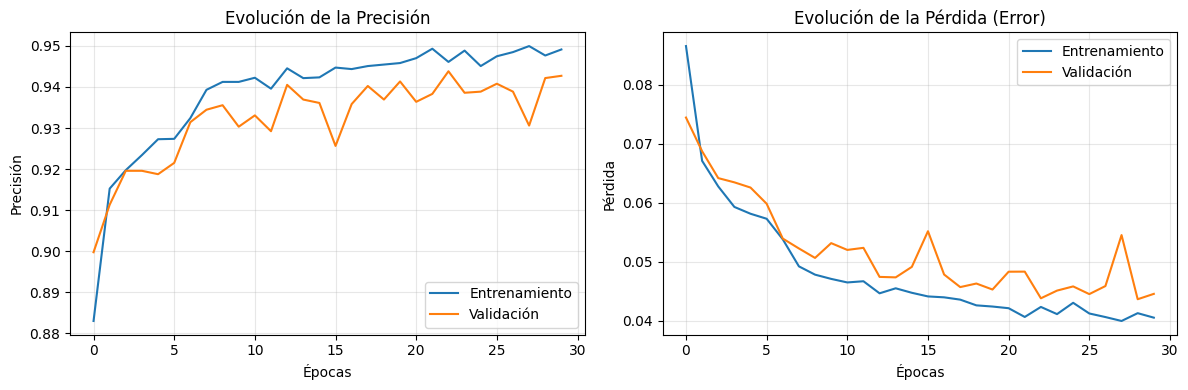

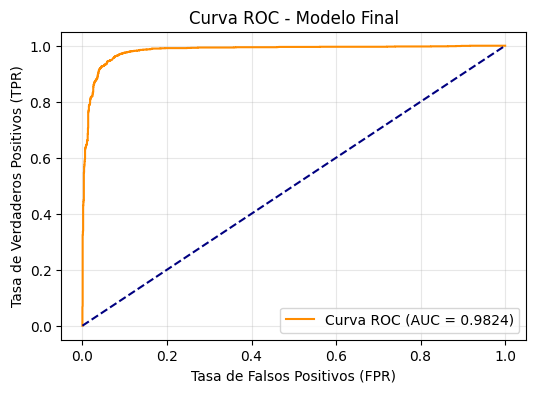

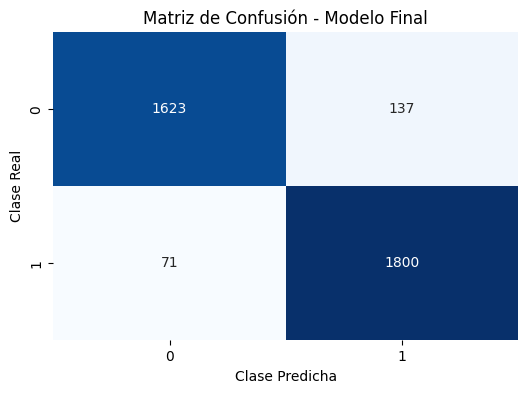

In [ ]:

# entrenamiento del modelo final con la configuracion elegida
modelo_final = keras.Sequential([
    layers.Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

optimizador_final = keras.optimizers.Adam(learning_rate=0.01)

modelo_final.compile(
    optimizer=optimizador_final,
    loss='mean_squared_error',
    metrics=['accuracy']
)

# Entrenamos el modelo y guardamos el historial para los gráficos
history_final = modelo_final.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=30,
    batch_size=16,
    verbose=1 #barra de progreso
)

print("Entrenamiento completado.")
# La red devuelve probabilidades por tener una función de activación sigmoide en la salida
y_pred_prob = modelo_final.predict(X_test)
# Convertimos probabilidades a clases binarias (0 o 1) usando un umbral de 0.5
y_pred_class = (y_pred_prob > 0.5).astype(int)

print("\n--- Cálculo de Métricas ---")
accuracy = accuracy_score(y_test, y_pred_class)
precision = precision_score(y_test, y_pred_class)
recall = recall_score(y_test, y_pred_class)
f1 = f1_score(y_test, y_pred_class)
auc_roc = roc_auc_score(y_test, y_pred_prob)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"AUC-ROC:   {auc_roc:.4f}")

# Curvas de Aprendizaje (Loss y Accuracy)
plt.figure(figsize=(12, 4))

# Curva de Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_final.history['accuracy'], label='Entrenamiento')
plt.plot(history_final.history['val_accuracy'], label='Validación')
plt.title('Evolución de la Precisión')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True, alpha=0.3)

# Curva de Loss
plt.subplot(1, 2, 2)
plt.plot(history_final.history['loss'], label='Entrenamiento')
plt.plot(history_final.history['val_loss'], label='Validación')
plt.title('Evolución de la Pérdida (Error)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 3. Curva ROC (Opcional pero muy recomendada para AUC-ROC)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'Curva ROC (AUC = {auc_roc:.4f})', color='darkorange')
plt.plot([0, 1], [0, 1], linestyle='--', color='navy')
plt.title('Curva ROC - Modelo Final')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

# Matriz de Confusión (VER SI DEJARLA, PUEDE SERVIR PARA COMPRAR CON CIENCIA DE DATOS)
cm = confusion_matrix(y_test, y_pred_class)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matriz de Confusión - Modelo Final')
plt.xlabel('Clase Predicha')
plt.ylabel('Clase Real')
plt.show()